
# Домашнее задание 3.2. Хаос в пищевой цепи

## 1. Математическая модель

Рассматривается безразмерная модель Hastings–Powell (1991), описывающая взаимодействие трёх популяций:

- $x(t)$ — жертвы;
- $y(t)$ — хищники;
- $z(t)$ — суперхищники.

Система дифференциальных уравнений:

$$
\begin{cases}
\dot{x}=x(1-x)-f_1(x)y,\\
\dot{y}=f_1(x)y-f_2(y)z-d_1y,\\
\dot{z}=f_2(y)z-d_2z,
\end{cases}
$$

где

$$
f_i(u)=\frac{a_i u}{1+b_i u}.
$$

Параметры модели:

$$
a_1=5,\quad a_2=0.1,\quad b_2=2,\quad
d_1=0.4,\quad d_2=0.01.
$$

Изменяемый параметр — $b_1$.

Начальные условия:

$$
x(0)=0.5,\qquad y(0)=0.1,\qquad z(0)=0.1.
$$

На первом этапе исследуем случай $b_1=3$ на интервале $0\le t\le 10000$.

Для построения аттрактора отбрасываем переходный процесс $0\le t<5000$.


In [42]:

import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp

# Параметры модели
a1 = 5.0
a2 = 0.1
b2 = 2.0
d1 = 0.4
d2 = 0.01

# Начальные условия
u0 = np.array([0.5, 0.1, 0.1])

# Временной интервал
T = 10000.0
T_transient = 5000.0

# Функции отклика
def f1(x, b1):
    return a1 * x / (1.0 + b1 * x)

def f2(y):
    return a2 * y / (1.0 + b2 * y)

# Правая часть системы Hastings-Powell
def hastings_powell(t, u, b1):
    x, y, z = u

    dx = x * (1.0 - x) - f1(x, b1) * y
    dy = f1(x, b1) * y - f2(y) * z - d1 * y
    dz = f2(y) * z - d2 * z

    return np.array([dx, dy, dz])


In [43]:

def integrate_system(
    b1,
    rtol=1e-9,
    atol=1e-11,
    max_step=2.0,
    method="DOP853"
):
    sol = solve_ivp(
        hastings_powell,
        t_span=(0.0, T),
        y0=u0,
        args=(b1,),
        method=method,
        rtol=rtol,
        atol=atol,
        max_step=max_step,
        dense_output=True
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    # Равномерная сетка для графиков
    t = np.arange(0.0, T + 1.0, 1.0)
    u = sol.sol(t)

    return sol, t, u


# Основной расчёт
b1 = 3.0

sol, t, u = integrate_system(b1)

x, y, z = u

print("Численное решение получено успешно.")
print(f"Число вычислений правой части: {sol.nfev}")
print()

# Проверка неотрицательности
names = ["x", "y", "z"]

for i, name in enumerate(names):
    minimum = min(np.min(sol.y[i]), np.min(u[i]))
    print(f"Минимальное значение {name}: {minimum:.8e}")

if np.all(sol.y >= 0) and np.all(u >= 0):
    print("\nВсе три популяции неотрицательны.")
else:
    print("\nОбнаружены отрицательные значения!")
    print("Необходимо проверить шаг интегрирования и допуски.")


Численное решение получено успешно.
Число вычислений правой части: 236666

Минимальное значение x: 4.67465388e-04
Минимальное значение y: 1.19625519e-02
Минимальное значение z: 9.99754641e-02

Все три популяции неотрицательны.


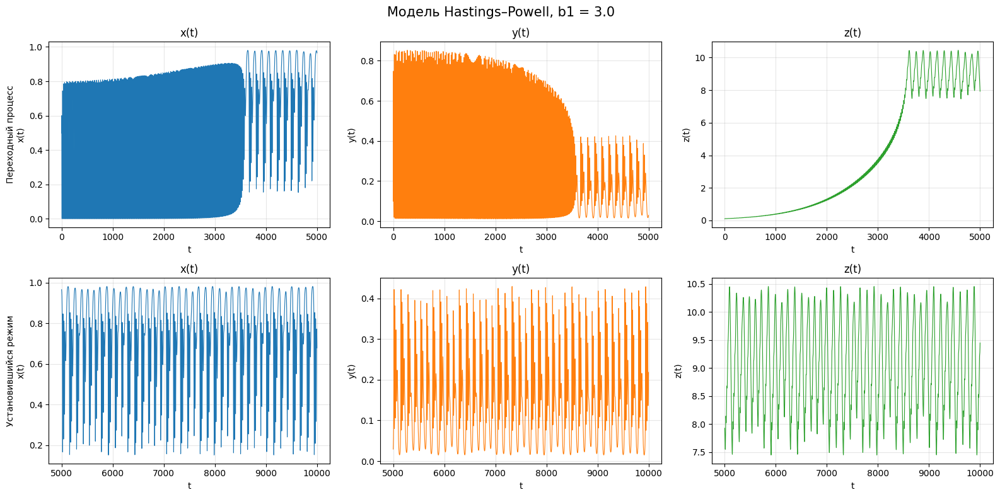

In [44]:

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

populations = [x, y, z]
names = ["x(t)", "y(t)", "z(t)"]
colors = ["tab:blue", "tab:orange", "tab:green"]

intervals = [
    (0, T_transient),
    (T_transient, T)
]

for row, (t_start, t_end) in enumerate(intervals):
    mask = (t >= t_start) & (t <= t_end)

    for col in range(3):
        ax = axes[row, col]

        ax.plot(
            t[mask],
            populations[col][mask],
            color=colors[col],
            linewidth=0.8
        )

        ax.set_title(names[col])
        ax.set_xlabel("t")
        ax.set_ylabel(names[col])
        ax.grid(alpha=0.3)

    title = (
        "Переходный процесс"
        if row == 0
        else "Установившийся режим"
    )

    axes[row, 0].set_ylabel(
        f"{title}\n{names[0]}"
    )

fig.suptitle(
    f"Модель Hastings–Powell, b1 = {b1}",
    fontsize=15
)

plt.tight_layout()
plt.show()


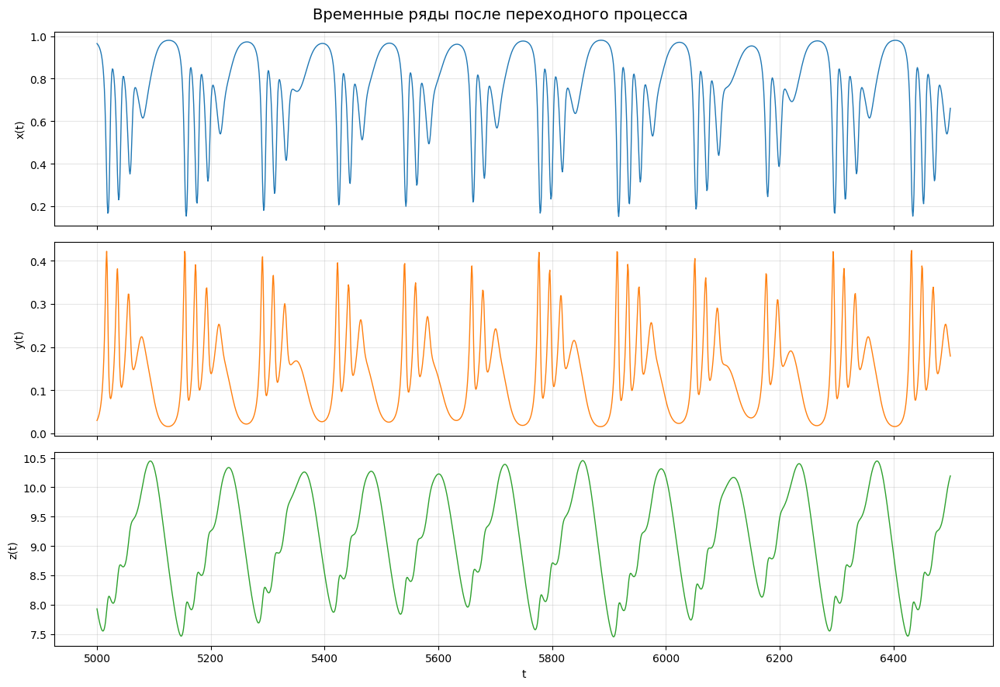

In [45]:

t_start = 5000
t_end = 6500

mask = (t >= t_start) & (t <= t_end)

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

for i, ax in enumerate(axes):
    ax.plot(
        t[mask],
        populations[i][mask],
        color=colors[i],
        linewidth=1
    )

    ax.set_ylabel(names[i])
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("t")

fig.suptitle(
    "Временные ряды после переходного процесса",
    fontsize=14
)

plt.tight_layout()
plt.show()


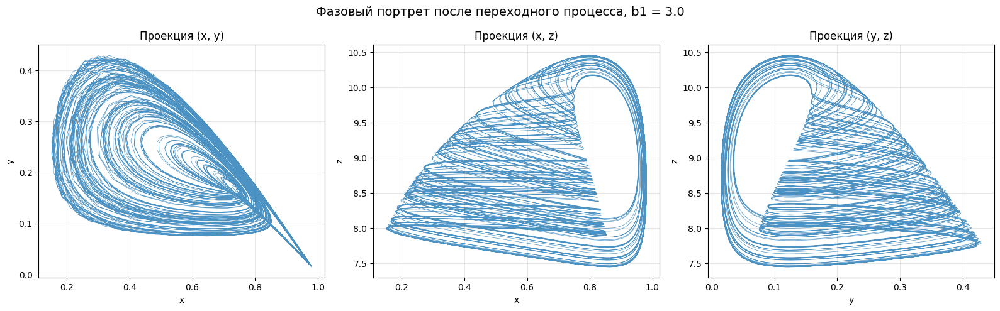

In [46]:
mask = t >= T_transient

x_attr = x[mask]
y_attr = y[mask]
z_attr = z[mask]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

projections = [
    (x_attr, y_attr, "x", "y"),
    (x_attr, z_attr, "x", "z"),
    (y_attr, z_attr, "y", "z")
]

for ax, (horizontal, vertical, xlabel, ylabel) in zip(
    axes, projections
):
    ax.plot(
        horizontal,
        vertical,
        linewidth=0.5,
        alpha=0.8
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f"Проекция ({xlabel}, {ylabel})")
    ax.grid(alpha=0.3)

fig.suptitle(
    f"Фазовый портрет после переходного процесса, b1 = {b1}",
    fontsize=14
)

plt.tight_layout()
plt.show()


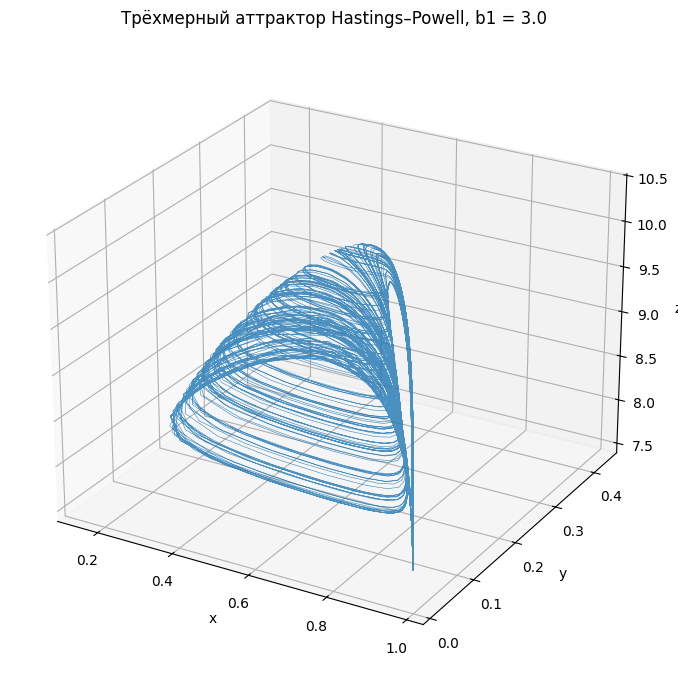

In [47]:

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    x_attr,
    y_attr,
    z_attr,
    color="tab:blue",
    linewidth=0.45,
    alpha=0.8
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title(
    f"Трёхмерный аттрактор Hastings–Powell, b1 = {b1}"
)

ax.view_init(elev=25, azim=-60)

plt.tight_layout()
plt.show()


In [48]:
# Повторный расчёт с более строгими настройками
sol_ref, t_ref, u_ref = integrate_system(
    b1=3.0,
    rtol=1e-11,
    atol=1e-13,
    max_step=1.0
)

# Восстанавливаем решения напрямую из интеграторов
U_base = sol.sol(t)
U_ref = sol_ref.sol(t_ref)

mask_base = t >= T_transient
mask_ref = t_ref >= T_transient

print("Сравнение численных расчётов\n")

print(f"Исходный расчёт: {sol.nfev} вычислений RHS")
print(f"Уточнённый расчёт: {sol_ref.nfev} вычислений RHS")

print("\nМинимальные значения популяций:")

for i, name in enumerate(["x", "y", "z"]):
    m1 = min(sol.y[i].min(), U_base[i].min())
    m2 = min(sol_ref.y[i].min(), U_ref[i].min())

    print(f"{name}: {m1:.6e} -> {m2:.6e}")

print("\nДиапазоны популяций на аттракторе:")

for i, name in enumerate(["x", "y", "z"]):
    v1 = U_base[i, mask_base]
    v2 = U_ref[i, mask_ref]

    print(f"\n{name}:")
    print(f"  Исходный:   [{v1.min():.5f}, {v1.max():.5f}]")
    print(f"  Уточнённый: [{v2.min():.5f}, {v2.max():.5f}]")

if np.all(sol_ref.y >= 0) and np.all(U_ref >= 0):
    print("\nУточнённое решение неотрицательно.")
else:
    print("\nОбнаружены отрицательные значения.")


Сравнение численных расчётов

Исходный расчёт: 236666 вычислений RHS
Уточнённый расчёт: 397064 вычислений RHS

Минимальные значения популяций:
x: 4.674654e-04 -> 4.659107e-04
y: 1.196255e-02 -> 1.196200e-02
z: 9.997546e-02 -> 9.996972e-02

Диапазоны популяций на аттракторе:

x:
  Исходный:   [0.15127, 0.98090]
  Уточнённый: [0.15122, 0.98089]

y:
  Исходный:   [0.01501, 0.42964]
  Уточнённый: [0.01501, 0.42906]

z:
  Исходный:   [7.45086, 10.45538]
  Уточнённый: [7.45128, 10.45521]

Уточнённое решение неотрицательно.



## 3. Сравнение динамических режимов

Рассмотрим два значения параметра:

$$
b_1=2.3,\qquad b_1=3.
$$

Для каждого значения численно решим систему Hastings–Powell на интервале $0\le t\le10000$, исключив переходный процесс $t<5000$.

Построим временные ряды и фазовые портреты.

**Цель:** сравнить регулярность колебаний и структуру аттракторов.

Для устойчивого предельного цикла характерны периодические временные ряды и замкнутая траектория в фазовом пространстве.

Для хаотического аттрактора характерны нерегулярные колебания и сложная незамкнутая траектория, остающаяся в ограниченной области фазового пространства.


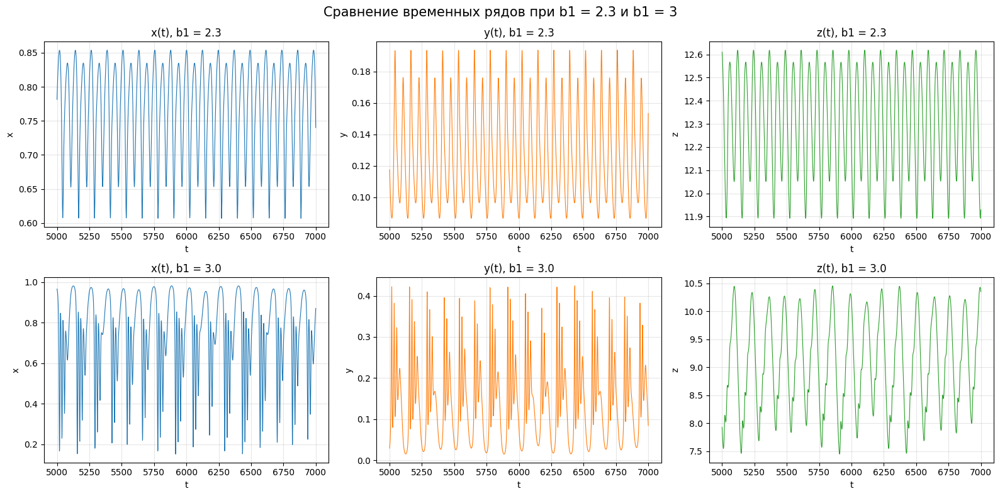

In [49]:

# Интегрируем систему для двух значений b1
sol_23, t_23, U_23 = integrate_system(b1=2.3)
sol_30, t_30, U_30 = integrate_system(b1=3.0)

results = [
    (2.3, t_23, U_23),
    (3.0, t_30, U_30)
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, (b, tt, uu) in enumerate(results):
    mask = (tt >= 5000) & (tt <= 7000)

    for j, name in enumerate(["x", "y", "z"]):
        ax = axes[i, j]

        ax.plot(
            tt[mask],
            uu[j, mask],
            color=colors[j],
            linewidth=0.8
        )

        ax.set_title(f"{name}(t), b1 = {b}")
        ax.set_xlabel("t")
        ax.set_ylabel(name)
        ax.grid(alpha=0.3)

fig.suptitle(
    "Сравнение временных рядов при b1 = 2.3 и b1 = 3",
    fontsize=15
)

plt.tight_layout()
plt.show()


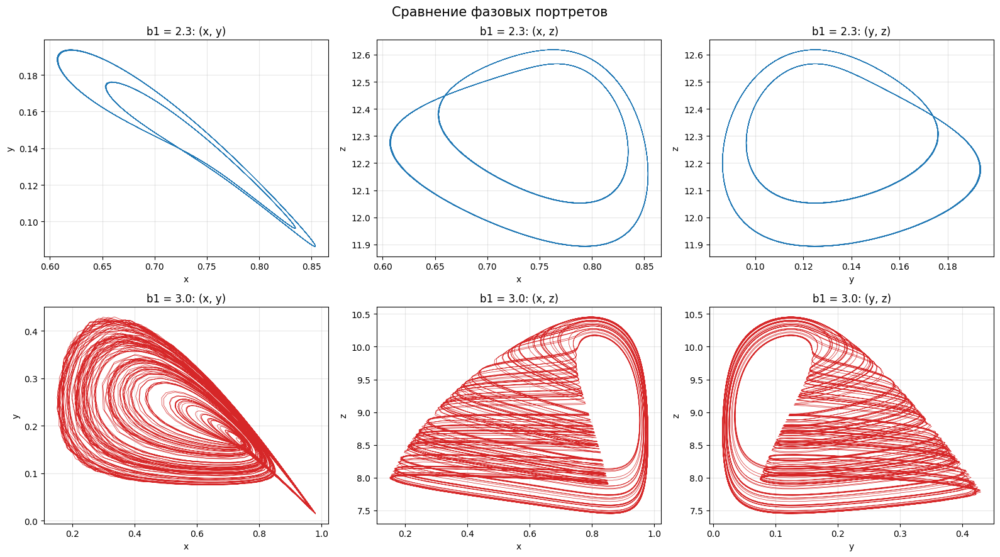

In [50]:

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, (b, tt, uu) in enumerate(results):
    mask = tt >= 5000

    xx, yy, zz = uu[:, mask]

    projections = [
        (xx, yy, "x", "y"),
        (xx, zz, "x", "z"),
        (yy, zz, "y", "z")
    ]

    for j, (a, c, xlabel, ylabel) in enumerate(projections):
        ax = axes[i, j]

        ax.plot(
            a, c,
            linewidth=0.5,
            color="tab:blue" if i == 0 else "tab:red"
        )

        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.set_title(f"b1 = {b}: ({xlabel}, {ylabel})")
        ax.grid(alpha=0.3)

fig.suptitle(
    "Сравнение фазовых портретов",
    fontsize=15
)

plt.tight_layout()
plt.show()



## 4. Старший показатель Ляпунова

Показатель Ляпунова характеризует среднюю экспоненциальную скорость роста малого возмущения траектории.

Пусть

$$
\mathbf{u}=(x,y,z)^T,\qquad
\dot{\mathbf{u}}=\mathbf{F}(\mathbf{u}).
$$

Для бесконечно малого возмущения $\delta\mathbf{u}$ справедливо вариационное уравнение:

$$
\frac{d}{dt}\delta\mathbf{u}
=
J(\mathbf{u})\delta\mathbf{u},
$$

где $J$ — матрица Якоби правой части системы.

Для модели Hastings–Powell:

$$
J=
\begin{pmatrix}
1-2x-f_1'(x)y & -f_1(x) & 0\\
f_1'(x)y & f_1(x)-f_2'(y)z-d_1 & -f_2(y)\\
0 & f_2'(y)z & f_2(y)-d_2
\end{pmatrix},
$$

причём

$$
f_i'(u)=\frac{a_i}{(1+b_i u)^2}.
$$

### Масштабирование координат

Популяции имеют существенно разные характерные величины. Поэтому введём постоянные масштабы:

$$
s_x=1,\qquad s_y=0.1,\qquad s_z=10.
$$

Определим масштабированное возмущение:

$$
\mathbf{q}=D^{-1}\delta\mathbf{u},
\qquad
D=\operatorname{diag}(1,0.1,10).
$$

Тогда

$$
\dot{\mathbf{q}}
=
D^{-1}J(\mathbf{u})D\mathbf{q}.
$$

Норму возмущения вычисляем в масштабированных координатах:

$$
\|\mathbf{q}\|_2=
\sqrt{
\left(\frac{\delta x}{1}\right)^2+
\left(\frac{\delta y}{0.1}\right)^2+
\left(\frac{\delta z}{10}\right)^2
}.
$$

**Эти масштабы используются без изменений для обоих значений $b_1$, всех переходных интервалов и всех настроек интегрирования.**

### Алгоритм с перенормировкой

1. Интегрируем исходную систему до аттрактора.
2. Задаём ненулевой вектор $\mathbf q_0$ единичной длины.
3. Совместно интегрируем исходную систему и вариационное уравнение на интервале $\Delta t$.
4. Вычисляем коэффициент роста:

$$
g_k=\|\mathbf q(t_k)\|_2.
$$

5. Перенормируем возмущение:

$$
\mathbf q(t_k)\leftarrow
\frac{\mathbf q(t_k)}{g_k}.
$$

6. Повторяем процедуру, накапливая логарифмы коэффициентов роста.

Оценка старшего показателя Ляпунова:

$$
\boxed{
\lambda_{\max}\approx
\frac{1}{T_{\mathrm{avg}}}
\sum_{k=1}^{N}\ln g_k
}
$$

Для автономной системы:

- $\lambda_{\max}>0$ — экспоненциальная чувствительность к начальным условиям, признак хаоса;
- $\lambda_{\max}\approx0$ — характерно для устойчивого предельного цикла;
- $\lambda_{\max}<0$ — характерно для устойчивого равновесия.

Для конечного времени усреднения показатель может немного отличаться от своего асимптотического значения.


In [51]:

# Постоянные масштабы популяций
POP_SCALES = np.array([1.0, 0.1, 10.0])


def hp_jacobian(u, b1):
    x, y, z = u

    F1 = f1(x, b1)
    F2 = f2(y)

    F1p = a1 / (1.0 + b1*x)**2
    F2p = a2 / (1.0 + b2*y)**2

    J = np.array([
        [1 - 2*x - F1p*y, -F1,              0.0],
        [F1p*y,           F1 - d1 - F2p*z, -F2],
        [0.0,             F2p*z,           F2 - d2]
    ])

    return J


def hp_variational_rhs(t, state, b1):
    # Расширенное состояние:
    # state = (x, y, z, qx, qy, qz)

    u = state[:3]
    q = state[3:]

    # Исходная система
    du = hastings_powell(t, u, b1)

    # Вариационное уравнение
    # dq/dt = D^(-1) J D q
    dq = hp_jacobian(u, b1) @ (POP_SCALES * q)
    dq /= POP_SCALES

    return np.concatenate((du, dq))


print("Масштабы координат:", POP_SCALES)
print("Матрица Якоби в начальной точке:")
print(hp_jacobian(u0, b1=3.0))


Масштабы координат: [ 1.   0.1 10. ]
Матрица Якоби в начальной точке:
[[-0.08       -1.          0.        ]
 [ 0.08        0.59305556 -0.00833333]
 [ 0.          0.00694444 -0.00166667]]


In [52]:

def max_lyapunov(
    b1,
    t_trans=5000.0,
    t_avg=5000.0,
    dt_renorm=10.0,
    tangent_warmup=200.0,
    rtol=1e-9,
    atol=1e-11,
    max_step=2.0
):
    if t_trans < tangent_warmup or t_avg <= 0 or dt_renorm <= 0:
        raise ValueError("Некорректные временные параметры")

    # 1. Интегрирование исходной системы
    # до начала подготовки направления возмущения
    t0 = t_trans - tangent_warmup

    if t0 > 0:
        sol = solve_ivp(
            hastings_powell,
            (0.0, t0),
            u0,
            args=(b1,),
            method="DOP853",
            rtol=rtol,
            atol=atol,
            max_step=max_step
        )

        if not sol.success:
            raise RuntimeError(sol.message)

        u_start = sol.y[:, -1]
    else:
        u_start = u0.copy()

    # 2. Начальное направление возмущения
    # в масштабированных координатах
    q0 = np.ones(3)
    q0 /= np.linalg.norm(q0)

    state = np.concatenate((u_start, q0))

    log_growth = 0.0
    elapsed = []
    estimates = []

    # 3. Два этапа:
    # подготовка направления и накопление показателя
    stages = [
        (t0, tangent_warmup, False),
        (t_trans, t_avg, True)
    ]

    for stage_start, duration, measure in stages:
        n_steps = int(np.ceil(duration / dt_renorm))

        for k in range(n_steps):
            t_left = stage_start + k * dt_renorm
            t_right = min(
                stage_start + (k + 1) * dt_renorm,
                stage_start + duration
            )

            # Совместное интегрирование u и q
            sol_step = solve_ivp(
                hp_variational_rhs,
                (t_left, t_right),
                state,
                args=(b1,),
                method="DOP853",
                rtol=rtol,
                atol=atol,
                max_step=max_step
            )

            if not sol_step.success:
                raise RuntimeError(sol_step.message)

            state = sol_step.y[:, -1].copy()

            # Рост возмущения в масштабированной норме
            growth = np.linalg.norm(state[3:])

            if growth <= 0 or not np.isfinite(growth):
                raise ArithmeticError(
                    "Некорректная норма возмущения"
                )

            # Перенормировка
            state[3:] /= growth

            # Учитываем рост только после t_trans
            if measure:
                log_growth += np.log(growth)

                duration_so_far = t_right - t_trans

                elapsed.append(duration_so_far)
                estimates.append(
                    log_growth / duration_so_far
                )

    return np.array(elapsed), np.array(estimates)


b1 = 2.3: lambda_max = 0.00009789
b1 = 3.0: lambda_max = 0.00717764


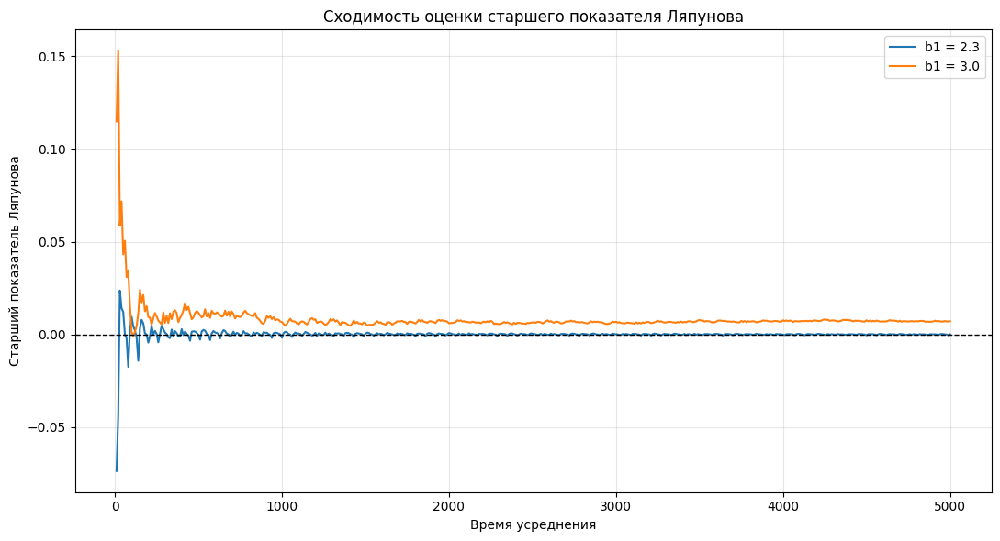

In [53]:

lyap_results = {}

for b in [2.3, 3.0]:
    times, lambdas = max_lyapunov(
        b1=b,
        t_trans=5000,
        t_avg=5000
    )

    lyap_results[b] = (times, lambdas)

    print(
        f"b1 = {b}: "
        f"lambda_max = {lambdas[-1]:.8f}"
    )

fig, ax = plt.subplots(figsize=(11, 6))

for b, (times, lambdas) in lyap_results.items():
    ax.plot(
        times,
        lambdas,
        linewidth=1.5,
        label=f"b1 = {b}"
    )

ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set_xlabel("Время усреднения")
ax.set_ylabel("Старший показатель Ляпунова")
ax.set_title("Сходимость оценки старшего показателя Ляпунова")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [54]:

# Набор численных экспериментов
test_cases = [
    ("Базовый расчёт", {}),
    ("Переход 2000", {"t_trans": 2000}),
    ("Переход 7000", {"t_trans": 7000}),
    ("Усреднение 2000", {"t_avg": 2000}),
    ("Усреднение 10000", {"t_avg": 10000}),
    ("Строгие допуски", {
        "rtol": 1e-11,
        "atol": 1e-13
    }),
    ("Меньший шаг", {"max_step": 1.0})
]

sensitivity_results = {}

print(f"{'Эксперимент':<24} {'b1 = 2.3':>14} {'b1 = 3':>14}")
print("-" * 54)

for label, params in test_cases:
    values = []

    for b in [2.3, 3.0]:
        if not params:
            # Используем ранее полученный базовый результат
            lam = lyap_results[b][1][-1]
        else:
            _, lambdas = max_lyapunov(b1=b, **params)
            lam = lambdas[-1]

        values.append(lam)

    sensitivity_results[label] = values

    print(
        f"{label:<24} "
        f"{values[0]:>14.7f} "
        f"{values[1]:>14.7f}"
    )


Эксперимент                    b1 = 2.3         b1 = 3
------------------------------------------------------
Базовый расчёт                0.0000979      0.0071776
Переход 2000                  0.0007997      0.0055657
Переход 7000                 -0.0001729      0.0069321
Усреднение 2000               0.0007929      0.0060517
Усреднение 10000              0.0000428      0.0070101
Строгие допуски               0.0000979      0.0060881
Меньший шаг                   0.0000979      0.0077532


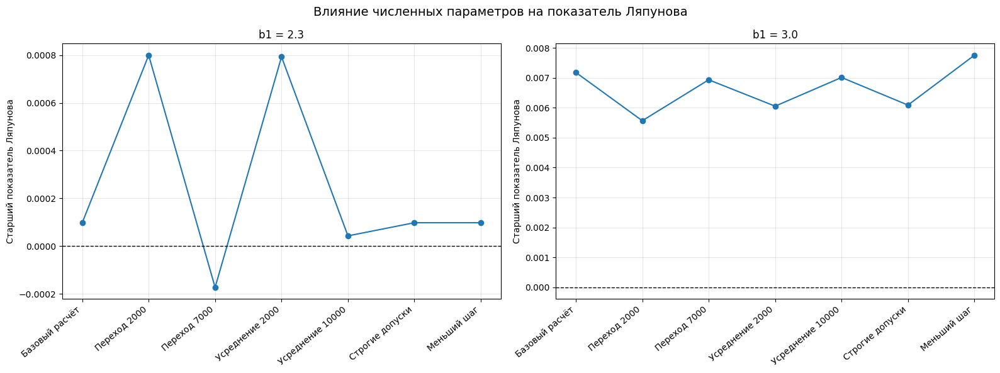

In [55]:

labels = list(sensitivity_results.keys())
values = np.array(list(sensitivity_results.values()))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for j, b in enumerate([2.3, 3.0]):
    ax = axes[j]

    ax.plot(
        range(len(labels)),
        values[:, j],
        marker="o",
        linewidth=1.5
    )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=40, ha="right")

    ax.set_title(f"b1 = {b}")
    ax.set_ylabel("Старший показатель Ляпунова")
    ax.grid(alpha=0.3)

fig.suptitle(
    "Влияние численных параметров на показатель Ляпунова",
    fontsize=14
)

plt.tight_layout()
plt.show()



## 7. Анимация динамики пищевой цепи

Для наглядной демонстрации движения по хаотическому аттрактору построим анимацию при $b_1=3$.

Слева изображается трёхмерная фазовая траектория $(x(t),y(t),z(t))$. Движущаяся точка показывает текущее состояние системы.

Справа представлены графики $x(t)$, $y(t)$ и $z(t)$. Положение маркеров и вертикальных линий соответствует тому же моменту времени, что и положение точки на фазовой траектории.

Рассматривается фрагмент установившегося режима после исключения переходного процесса.

Анимация позволяет проследить связь между изменениями численности популяций и движением системы в фазовом пространстве.


In [57]:

from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

plt.rcParams["animation.embed_limit"] = 60

# Выбираем участок установившегося режима
anim_mask = (t_30 >= 5000) & (t_30 <= 5500)

# Прореживаем временную сетку для анимации
anim_t = t_30[anim_mask][::5]
anim_U = U_30[:, anim_mask][:, ::5]

# Полный аттрактор для отображения фона
attr_mask = t_30 >= T_transient
attr_U = U_30[:, attr_mask]

# Компоновка: 3D-портрет слева, три графика справа
fig = plt.figure(figsize=(13, 7))
gs = fig.add_gridspec(
    3, 2,
    width_ratios=[1.3, 1],
    hspace=0.4,
    wspace=0.3
)

ax3d = fig.add_subplot(gs[:, 0], projection="3d")
axes_ts = [fig.add_subplot(gs[i, 1]) for i in range(3)]

# Полная фазовая траектория серым цветом
ax3d.plot(
    attr_U[0, ::8],
    attr_U[1, ::8],
    attr_U[2, ::8],
    color="lightgray",
    linewidth=0.6
)

# Пройденная часть траектории
phase_line, = ax3d.plot(
    [], [], [],
    color="tab:blue",
    linewidth=1.5
)

# Движущаяся точка
phase_point, = ax3d.plot(
    [], [], [],
    "ro",
    markersize=6
)

ax3d.set_xlabel("x")
ax3d.set_ylabel("y")
ax3d.set_zlabel("z")
ax3d.set_title("Фазовая траектория")

# Фиксированные пределы осей
for j, setter in enumerate([
    ax3d.set_xlim,
    ax3d.set_ylim,
    ax3d.set_zlim
]):
    lo = attr_U[j].min()
    hi = attr_U[j].max()
    pad = 0.05 * (hi - lo)
    setter(lo - pad, hi + pad)

# Графики популяций
ts_lines = []
ts_points = []
ts_cursors = []

names_anim = ["x(t)", "y(t)", "z(t)"]
colors_anim = ["tab:blue", "tab:orange", "tab:green"]

for j, ax in enumerate(axes_ts):
    # Фоновый временной ряд
    ax.plot(
        anim_t,
        anim_U[j],
        color="lightgray",
        linewidth=0.8
    )

    # Пройденный участок графика
    line, = ax.plot(
        [], [],
        color=colors_anim[j],
        linewidth=1.5
    )

    # Текущее состояние популяции
    point, = ax.plot([], [], "ro", markersize=5)

    # Вертикальная линия текущего времени
    cursor = ax.axvline(
        anim_t[0],
        color="red",
        linestyle="--",
        linewidth=0.8
    )

    ts_lines.append(line)
    ts_points.append(point)
    ts_cursors.append(cursor)

    ax.set_xlim(anim_t[0], anim_t[-1])

    lo = attr_U[j].min()
    hi = attr_U[j].max()
    pad = 0.05 * (hi - lo)
    ax.set_ylim(lo - pad, hi + pad)

    ax.set_ylabel(names_anim[j])
    ax.grid(alpha=0.3)

axes_ts[-1].set_xlabel("t")


def update(frame):
    k = frame

    # Пройденный участок фазовой траектории
    phase_line.set_data(
        anim_U[0, :k+1],
        anim_U[1, :k+1]
    )
    phase_line.set_3d_properties(anim_U[2, :k+1])

    # Движущаяся точка
    phase_point.set_data(
        [anim_U[0, k]],
        [anim_U[1, k]]
    )
    phase_point.set_3d_properties([anim_U[2, k]])

    # Синхронное обновление временных рядов
    for j in range(3):
        ts_lines[j].set_data(
            anim_t[:k+1],
            anim_U[j, :k+1]
        )

        ts_points[j].set_data(
            [anim_t[k]],
            [anim_U[j, k]]
        )

        ts_cursors[j].set_xdata(
            [anim_t[k], anim_t[k]]
        )

    fig.suptitle(
        f"Hastings–Powell, b1 = 3, t = {anim_t[k]:.1f}",
        fontsize=14
    )

    return (
        [phase_line, phase_point]
        + ts_lines
        + ts_points
        + ts_cursors
    )


anim = FuncAnimation(
    fig,
    update,
    frames=len(anim_t),
    interval=50,
    blit=False,
    repeat=False
)

plt.close(fig)

# Отображаем анимацию прямо в Jupyter Notebook
display(HTML(anim.to_jshtml(fps=20, default_mode="once")))
